# 作业 03　NumPy、Matplotlib 与 pandas

姓名：欧阳洋　　学号：20244080124

In [1]:
import hashlib
import os
import platform
import sys
import uuid

STUDENT_ID = 20244080124
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")
print(f"[Python]    {sys.version.split()[0]}")

[Conda 环境] python_work1
[学号]       20244080124
[机器指纹] 66ab728912afd30e
[RUN_ID]   20244080124-66ab728912afd30e
[Python]    3.12.15


## 一、Wigner 半圆定律

上三角（含对角线）的元素独立从 $N(0,1/n)$ 抽取，NumPy 的 `scale` 传入标准差 $1/\sqrt{n}$。
将上三角镜像到下三角后，矩阵为实对称矩阵，因此可用 `eigvalsh()` 直接得到非递减排列的实特征值。
半圆密度在 $[-2,2]$ 内为 $\sqrt{4-x^2}/(2\pi)$，区间外为 0。

In [2]:
# 为未配置线程数的 OpenBLAS 设置单线程，避免在本机初始化线程池时出错。
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(STUDENT_ID)


def wigner_density(x):
    """返回半圆密度在 x 处的值。"""
    if x < -2 or x > 2:
        return 0.0
    return float(np.sqrt(4.0 - float(x) ** 2) / (2 * np.pi))


def generate_wigner(n):
    """独立抽取上三角元素，再将严格上三角镜像到下三角。"""
    if isinstance(n, (bool, np.bool_)) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")

    n = int(n)
    rows, cols = np.triu_indices(n)
    samples = rng.normal(loc=0.0, scale=1.0 / np.sqrt(n), size=rows.size)
    matrix = np.empty((n, n))
    matrix[rows, cols] = samples
    matrix[cols, rows] = samples
    return matrix


def get_spectrum(matrix):
    """返回对称矩阵按非递减顺序排列的全部特征值。"""
    return np.linalg.eigvalsh(matrix)

In [3]:
# 检查密度函数、矩阵对称性、特征值与非法阶数。
print("在 x = -2, 0, 2, 3 处的密度：",
      [wigner_density(x) for x in (-2, np.float64(0), np.int64(2), 3.0)])
example = generate_wigner(np.int64(3))
print("矩阵形状：", example.shape, "  是否对称：", np.array_equal(example, example.T))
print("特征值：", get_spectrum(example))

for invalid_n in (2.5, 0, -1, True):
    try:
        generate_wigner(invalid_n)
    except (TypeError, ValueError) as error:
        print(f"n={invalid_n!r}：{type(error).__name__}，{error}")

在 x = -2, 0, 2, 3 处的密度： [0.0, 0.3183098861837907, 0.0, 0.0]
矩阵形状： (3, 3)   是否对称： True
特征值： [-1.49316584  0.14486297  0.64502448]
n=2.5：TypeError，n 必须是整数
n=0：ValueError，n 必须是正整数
n=-1：ValueError，n 必须是正整数
n=True：TypeError，n 必须是整数


四个子图使用相同的分箱边界和坐标范围。蓝色直方图按密度归一化，总面积为 1，可与红色的理论密度曲线直接比较。

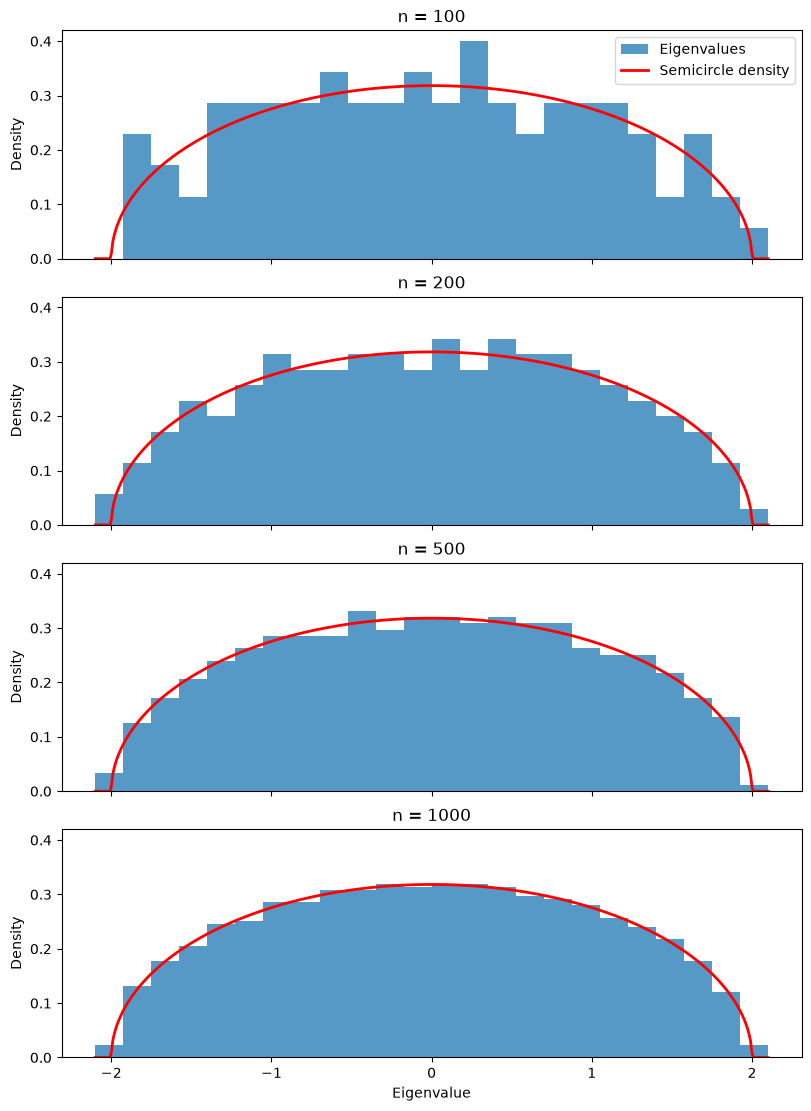

In [4]:
rng = np.random.default_rng(STUDENT_ID)
sizes = (100, 200, 500, 1000)
spectra = [get_spectrum(generate_wigner(n)) for n in sizes]
limit = max(2.1, max(np.max(np.abs(values)) for values in spectra))
bin_edges = np.linspace(-limit, limit, 25)
x_values = np.linspace(-limit, limit, 500)
density_values = [wigner_density(x) for x in x_values]

fig, axes = plt.subplots(4, 1, figsize=(8, 11), sharex=True, sharey=True,
                         layout="constrained")
for ax, n, eigenvalues in zip(axes, sizes, spectra):
    ax.hist(eigenvalues, bins=bin_edges, density=True, color="tab:blue",
            alpha=0.75, label="Eigenvalues")
    ax.plot(x_values, density_values, color="red", linewidth=2,
            label="Semicircle density")
    ax.set_title(f"n = {n}")
    ax.set_ylabel("Density")

axes[0].legend()
axes[-1].set_xlabel("Eigenvalue")
plt.show()

### 拟合观察

在这组固定种子的模拟中，$n=100$ 的柱高起伏明显，$n=200$ 时已能看出半圆轮廓。
$n$ 约为 **500** 时，大多数柱高已较贴近红色曲线，$n=1000$ 时更平滑。
这个估计来自本次抽样和分箱下的图形比较。

## 二、Conway 的生命游戏

`gol_step()` 对原棋盘做八次环绕平移并累加，得到每个格子的活邻居数。恰有三个活邻居的格子在下一代为活，
恰有两个活邻居的格子维持原状态，其余格子在下一代为死。计算结果放到新数组中，同时完成所有格子的更新。

In [5]:
def is_valid_board(board):
    """判断输入是否为只含 0 和 1 的二维 NumPy 数组。"""
    return (
        isinstance(board, np.ndarray)
        and board.ndim == 2
        and bool(np.isin(board, (0, 1)).all())
    )


def gol_step(board):
    """使用环绕边界和同一代的邻居状态计算下一代。"""
    if not is_valid_board(board):
        raise ValueError("棋盘必须是只含 0 和 1 的二维 NumPy 数组")

    live = board == 1
    neighbors = np.zeros(board.shape, dtype=np.uint8)
    for row_shift in (-1, 0, 1):
        for col_shift in (-1, 0, 1):
            if (row_shift, col_shift) != (0, 0):
                neighbors += np.roll(live, (row_shift, col_shift), axis=(0, 1))

    return ((neighbors == 3) | (live & (neighbors == 2))).astype(int)


def draw_gol_board(board):
    """绘制黑色活细胞和白色死细胞。"""
    _, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(board, cmap="binary", vmin=0, vmax=1,
              interpolation="nearest", aspect="equal")
    ax.set_axis_off()
    plt.show()

初始棋盘：


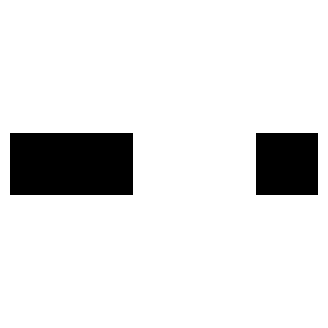

一步后的棋盘：


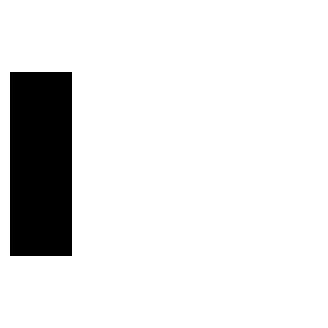

一步后活细胞坐标： [[1, 0], [2, 0], [3, 0]]
两步后复原： True
原棋盘保持原值： True
含 2 的数组是否有效： False
ValueError：棋盘必须是只含 0 和 1 的二维 NumPy 数组


In [6]:
# 三个活细胞横跨左右边界，一步后变成竖直排列，两步回到原状态。
board = np.zeros((5, 5), dtype=int)
board[2, [4, 0, 1]] = 1
before = board.copy()
next_board = gol_step(board)
print("初始棋盘：")
draw_gol_board(board)
print("一步后的棋盘：")
draw_gol_board(next_board)
print("一步后活细胞坐标：", np.argwhere(next_board).tolist())
print("两步后复原：", np.array_equal(gol_step(next_board), before))
print("原棋盘保持原值：", np.array_equal(board, before))

invalid = np.array([[0, 2]])
print("含 2 的数组是否有效：", is_valid_board(invalid))
try:
    gol_step(invalid)
except ValueError as error:
    print(f"{type(error).__name__}：{error}")

## 三、使用 pandas 处理 Iris 数据

### 3.1 读取 CSV 并查看数据结构

读取课程群共享的 Iris 数据，文件以 `iris_course.csv` 保存于本目录。原表有 150 条记录和 6 列。
`Id` 是记录编号，另外四个数值列分别为萼片长度、萼片宽度、花瓣长度和花瓣宽度，单位为厘米。
`Species` 是原表提供的物种标签，三个物种各有 50 条记录。

展示原表结构后，去掉编号列，将四个测量列改为简明列名，并从物种标签去掉 `Iris-` 前缀。

In [7]:
import pandas as pd
from IPython.display import display

iris_source = pd.read_csv("iris_course.csv", header=0, dtype={"Species": "string"})
print("原始列名：", iris_source.columns.tolist())
print("数据点数：", len(iris_source))
print("花卉种数：", iris_source["Species"].nunique())
display(iris_source.dtypes.astype(str).rename("数据类型").to_frame())
display(iris_source["Species"].value_counts().rename("记录数").to_frame())
display(iris_source.head())

measurement_columns = {
    "SepalLengthCm": "Sepal.Length",
    "SepalWidthCm": "Sepal.Width",
    "PetalLengthCm": "Petal.Length",
    "PetalWidthCm": "Petal.Width",
}
iris = iris_source.drop(columns="Id").rename(columns=measurement_columns)
iris["Species"] = iris["Species"].str.removeprefix("Iris-")

原始列名： ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
数据点数： 150
花卉种数： 3


,数据类型
Id,int64
SepalLengthCm,float64
SepalWidthCm,float64
PetalLengthCm,float64
PetalWidthCm,float64
Species,string


,记录数
Species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


### 3.2 修正题目指定的两行

数据行从 1 开始计数，不包含表头。第 35、38 行分别对应索引 34、37。
第 35 行的花瓣宽度由 `0.1` 修正为 `0.2`。第 38 行的萼片宽度由 `3.1` 修正为 `3.6`，花瓣长度由 `1.5` 修正为 `1.4`。

In [8]:
# 数据行从 1 开始计数，第 35 和 38 行对应索引 34 和 37。
columns = ["Sepal.Length", "Sepal.Width", "Petal.Length", "Petal.Width", "Species"]
iris.loc[34, columns] = [4.9, 3.1, 1.5, 0.2, "setosa"]
iris.loc[37, columns] = [4.9, 3.6, 1.4, 0.1, "setosa"]
display(iris.loc[[34, 37]])

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
34,4.9,3.1,1.5,0.2,setosa
37,4.9,3.6,1.4,0.1,setosa


### 3.3 计算比值并导出 CSV

`Petal.Ratio` 是花瓣长除以花瓣宽，`Sepal.Ratio` 是萼片长除以萼片宽。两列都是无单位的比值。

In [9]:
iris["Petal.Ratio"] = iris["Petal.Length"] / iris["Petal.Width"]
iris["Sepal.Ratio"] = iris["Sepal.Length"] / iris["Sepal.Width"]

output_path = "iris_corrected.csv"
iris.to_csv(output_path, index=False)
print(f"已保存 {output_path}，共 {len(iris)} 行、{iris.shape[1]} 列")
display(iris[["Petal.Ratio", "Sepal.Ratio"]].head())

已保存 iris_corrected.csv，共 150 行、7 列


,Petal.Ratio,Sepal.Ratio
0,7.0,1.457143
1,7.0,1.633333
2,6.5,1.468750
3,7.5,1.483871
4,7.0,1.388889


### 3.4 按物种汇总

以 `Species` 分组，对两列比值一次计算均值、中位数、最小值、最大值和样本标准差（`ddof=1`）。

In [10]:
summary = iris.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
display(summary)

Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
Species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
Species                                             
setosa      1.463063  1.268293  1.956522  0.118750  
versicolor  2.161290  1.764706  2.818182  0.228658  
virginica   2.169540  1.823529  2.961538  0.246992

提交时将本 Notebook 与生成的 `iris_corrected.csv` 一并提交。